# Sujet 9 — Classer les incidents IT avec le jeu Tobi-Bueck

Ce notebook reprend la démarche du TP2 de `sentiment-app`, appliquée au support informatique :

1. charger le jeu réel **Tobi-Bueck/customer-support-tickets** (Hugging Face, CC BY-NC 4.0) ;
2. l'explorer, puis garder **ce dont le projet a besoin** : les tickets en anglais, de type *Incident* ;
3. **découper avant toute transformation**, entraîner TF-IDF + régression logistique ;
4. mesurer : accuracy, F1 macro, F1 pondéré, rappel par classe, matrice de confusion ;
5. mesurer la **courbe du seuil d'abstention** (l'équivalent de `courbe_seuil.py`) ;
6. entraîner un second modèle pour la **priorité** (règle d'escalade) ;
7. **tester sur des incidents réels** : catégorie, confiance, priorité, décision (solution ou escalade)
   et la réponse d'un ticket passé semblable, tirée de la colonne `answer` ;
8. sauvegarder les modèles et `metrics.json`.

Tout s'exécute de haut en bas, sur Colab ou en local (Python 3.11).

## 1. Installation et imports

In [1]:
import os

# Sur Colab ou dans un environnement neuf. Mettre SKIP_INSTALL=1 pour sauter cette cellule.
if os.environ.get("SKIP_INSTALL") != "1":
    %pip install -q datasets "scikit-learn>=1.5,<1.6" pandas matplotlib joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, recall_score)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

GRAINE = 42
SEUIL_F1 = 0.85            # le seuil du cours : à comparer, pas à truquer
MIN_PAR_QUEUE = int(os.environ.get("MIN_PAR_QUEUE", 200))  # une catégorie plus rare est écartée (trop peu d'exemples pour apprendre)
pd.set_option("display.max_colwidth", 120)

## 2. Charger le jeu de données

Par défaut, le notebook télécharge le jeu depuis Hugging Face. Si vous l'avez téléchargé
vous-même (Hugging Face ou Kaggle), indiquez le chemin du CSV dans `CSV_LOCAL`.

In [3]:
CSV_LOCAL = os.environ.get("TOBI_CSV")   # exemple : "data/aa_dataset-tickets-multi-lang.csv"

if CSV_LOCAL:
    brut = pd.read_csv(CSV_LOCAL)
    source = f"csv:{Path(CSV_LOCAL).name}"
else:
    from datasets import load_dataset
    brut = load_dataset("Tobi-Bueck/customer-support-tickets", split="train").to_pandas()
    source = "huggingface:Tobi-Bueck/customer-support-tickets"

brut.columns = [c.strip().lower() for c in brut.columns]
print(source, brut.shape)
brut.head(3)

huggingface:Tobi-Bueck/customer-support-tickets (61765, 16)


,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte einen gravierenden Sicherheitsvorfall melden, der gegenwärtig mehrere Komp...",Vielen Dank für die Meldung des kritischen Sicherheitsvorfalls und die Bereitstellung der Übersicht über die betroff...,Incident,Technical Support,high,de,51.0,Security,Outage,Disruption,Data Breach,None,None,None,None
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to report a significant problem with the centralized account management ...","Thank you for reaching out, <name>. We are aware of the outage affecting the centralized account management system, ...",Incident,Technical Support,high,en,51.0,Account,Disruption,Outage,IT,Tech Support,None,None,None
2,Query About Smart Home System Integration Features,"Dear Customer Support Team,\n\nI hope this message reaches you well. I am reaching out to request detailed informati...","Thank you for your inquiry. Our products support integration with Amazon Alexa, Google Assistant, and Apple HomeKit....",Request,Returns and Exchanges,medium,en,51.0,Product,Feature,Tech Support,None,None,None,None,None


## 3. Explorer avant de choisir

In [4]:
print("Colonnes :", list(brut.columns))
print("\nValeurs manquantes :")
print(brut[["subject", "body", "answer", "type", "queue", "priority", "language"]].isna().sum())
for colonne in ["language", "type", "priority"]:
    print(f"\n{colonne} :")
    print(brut[colonne].value_counts(dropna=False))

Colonnes : ['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']

Valeurs manquantes :
subject      5299
body            2
answer      13189
type        13178
queue           0
priority        0
language        0
dtype: int64

language :
language
de    33504
en    28261
Name: count, dtype: int64

type :
type
Incident    19444
Request     13950
None        13178
Problem     10196
Change       4997
Name: count, dtype: int64

priority :
priority
medium      23378
high        21925
low         12765
critical     1914
very_low     1783
Name: count, dtype: int64


In [5]:
print("Nombre de queues :", brut["queue"].nunique())
brut["queue"].value_counts().head(30)

Nombre de queues : 52


queue
Technical Support                       14186
Product Support                          8960
Customer Service                         7420
IT Support                               5725
Billing and Payments                     4874
Returns and Exchanges                    2438
Service Outages and Maintenance          1912
Sales and Pre-Sales                      1490
Human Resources                           914
General Inquiry                           668
Pets & Animals/Pet Services               386
News                                      383
IT & Technology/Security Operations       365
Autos & Vehicles/Sales                    364
Health/Medical Services                   362
Home & Garden/Home Improvement            361
Pets & Animals/Veterinary Care            356
Health/Mental Health                      347
Business & Industrial/Manufacturing       346
Online Communities/Forums                 343
Shopping/E-commerce                       341
Food & Drink/Groceries      

## 4. Garder ce dont le projet a besoin

- **langue anglaise** : le modèle ne doit apprendre qu'une langue ;
- **type Incident** : la priorité du projet (quelque chose qui marchait et ne marche plus) ;
- **texte** = sujet + corps ; tickets vides et doublons retirés ;
- **queues assez fréquentes** (au moins `MIN_PAR_QUEUE` incidents), les autres sont écartées et comptées.

In [6]:
df = brut.copy()
for colonne in ["language", "type", "priority", "queue"]:
    df[colonne] = df[colonne].astype("string").str.strip()

df = df[df["language"].str.lower() == "en"]
print("Anglais :", len(df))
df = df[df["type"].str.lower() == "incident"]
print("Anglais + Incident :", len(df))

df["text"] = (df["subject"].fillna("") + " " + df["body"].fillna("")).str.strip()
df = df[df["text"].str.split().str.len() >= 3]
df = df.drop_duplicates(subset="text")
df["priority"] = df["priority"].str.lower()
print("Après nettoyage :", len(df))

comptes = df["queue"].value_counts()
gardees = comptes[comptes >= MIN_PAR_QUEUE].index.tolist()
ecartees = comptes[comptes < MIN_PAR_QUEUE]
df = df[df["queue"].isin(gardees)].reset_index(drop=True)
print(f"\n{len(gardees)} queues gardées, {len(ecartees)} écartées ({ecartees.sum()} tickets)")
assert len(gardees) >= 2, "Moins de deux queues : baissez MIN_PAR_QUEUE"
df["queue"].value_counts()

Anglais : 28261
Anglais + Incident : 11213
Après nettoyage : 9431

8 queues gardées, 2 écartées (252 tickets)


queue
Technical Support                  3548
Product Support                    1945
IT Support                          998
Customer Service                    916
Billing and Payments                574
Service Outages and Maintenance     517
Returns and Exchanges               450
Human Resources                     231
Name: count, dtype: Int64

9179 incidents, 8 classes
Longueur des tickets : médiane 58 mots, max 235

Priorités :
priority
high      3999
medium    3541
low       1639
Name: count, dtype: Int64


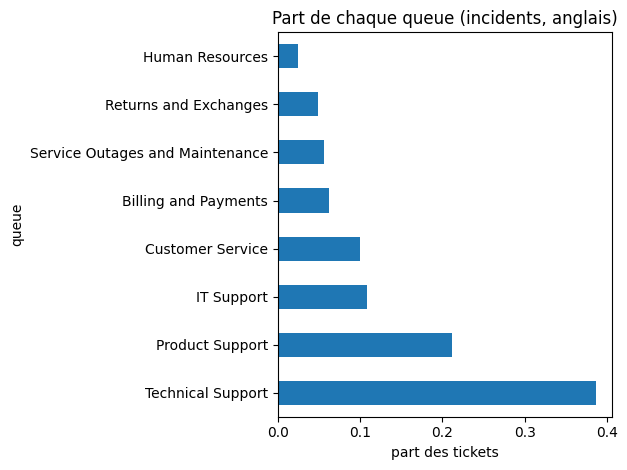

In [7]:
mots = df["text"].str.split().str.len()
print(f"{len(df)} incidents, {df['queue'].nunique()} classes")
print(f"Longueur des tickets : médiane {mots.median():.0f} mots, max {mots.max()}")
print("\nPriorités :")
print(df["priority"].value_counts())
df["queue"].value_counts(normalize=True).plot.barh(title="Part de chaque queue (incidents, anglais)")
plt.xlabel("part des tickets"); plt.tight_layout(); plt.show()

## 5. Découper avant toute transformation

Le jeu de test (20 %) est mis de côté **avant** la vectorisation : sinon son vocabulaire fuirait dans
l'entraînement. `stratify` garde la même part de chaque queue des deux côtés.

In [8]:
x_train, x_test, y_train, y_test, idx_train, idx_test = train_test_split(
    df["text"], df["queue"], df.index, test_size=0.2, random_state=GRAINE, stratify=df["queue"])
print(f"{len(x_train)} tickets d'entraînement, {len(x_test)} de test")

7343 tickets d'entraînement, 1836 de test


## 6. Entraîner et mesurer

Trois modèles, pour savoir si le score veut dire quelque chose :
- **référence naïve** : répond toujours la queue la plus fréquente ;
- **TF-IDF + régression logistique** : le modèle du cours (il donne une confiance, utile pour l'abstention) ;
- **TF-IDF + LinearSVC** : un concurrent classique, pour comparer.

In [9]:
def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=100_000)

modeles = {
    "Référence naïve": DummyClassifier(strategy="most_frequent"),
    "TF-IDF + régression logistique": Pipeline([
        ("tfidf", tfidf()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=GRAINE)),
    ]),
    "TF-IDF + LinearSVC": Pipeline([
        ("tfidf", tfidf()),
        ("clf", LinearSVC(class_weight="balanced", random_state=GRAINE)),
    ]),
}

lignes = []
for nom, modele in modeles.items():
    modele.fit(x_train, y_train)
    predits = modele.predict(x_test)
    lignes.append({
        "modèle": nom,
        "accuracy": accuracy_score(y_test, predits),
        "F1 macro": f1_score(y_test, predits, average="macro"),
        "F1 pondéré": f1_score(y_test, predits, average="weighted"),
    })
comparaison = pd.DataFrame(lignes).set_index("modèle").round(3)
comparaison

,accuracy,F1 macro,F1 pondéré
modèle,,,
Référence naïve,0.387,0.070,0.216
TF-IDF + régression logistique,0.558,0.592,0.562
TF-IDF + LinearSVC,0.684,0.693,0.682


In [10]:
modele = modeles["TF-IDF + régression logistique"]
predits = modele.predict(x_test)
f1_macro = f1_score(y_test, predits, average="macro")
print(f"Vocabulaire : {len(modele.named_steps['tfidf'].vocabulary_)} termes")
print(f"F1 macro : {f1_macro:.3f} (seuil du cours {SEUIL_F1}) -> "
      f"{'atteint' if f1_macro >= SEUIL_F1 else 'NON atteint : à expliquer dans semaine2.md'}\n")
print(classification_report(y_test, predits, digits=3, zero_division=0))

Vocabulaire : 30467 termes
F1 macro : 0.592 (seuil du cours 0.85) -> NON atteint : à expliquer dans semaine2.md

                                 precision    recall  f1-score   support

           Billing and Payments      1.000     0.835     0.910       115
               Customer Service      0.426     0.470     0.447       183
                Human Resources      0.592     0.630     0.611        46
                     IT Support      0.376     0.555     0.448       200
                Product Support      0.508     0.470     0.489       389
          Returns and Exchanges      0.492     0.667     0.566        90
Service Outages and Maintenance      0.589     0.806     0.680       103
              Technical Support      0.658     0.530     0.587       710

                       accuracy                          0.558      1836
                      macro avg      0.580     0.620     0.592      1836
                   weighted avg      0.580     0.558     0.562      1836



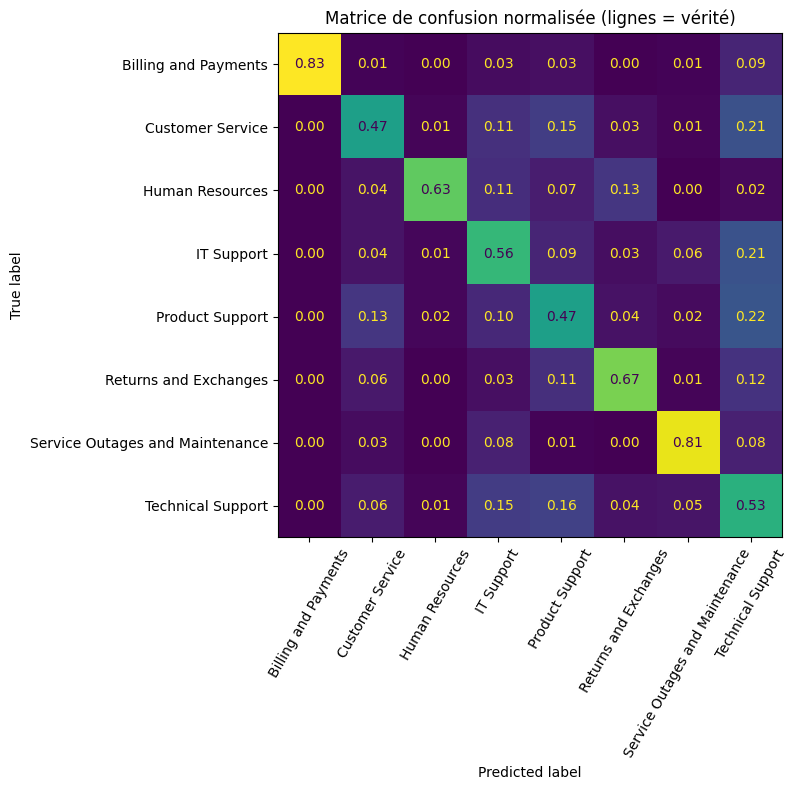

In [11]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, predits, normalize="true", values_format=".2f",
                                        xticks_rotation=60, ax=ax, colorbar=False)
ax.set_title("Matrice de confusion normalisée (lignes = vérité)")
plt.tight_layout(); plt.show()

## 7. Lire les erreurs

In [12]:
erreurs = pd.DataFrame({"vérité": y_test, "prédit": predits, "texte": x_test})
erreurs = erreurs[erreurs["vérité"] != erreurs["prédit"]]
print(f"{len(erreurs)} erreurs sur {len(y_test)}\n")
print("Confusions les plus fréquentes :")
print(erreurs.groupby(["vérité", "prédit"]).size().sort_values(ascending=False).head(8))
erreurs.sample(min(8, len(erreurs)), random_state=GRAINE)

812 erreurs sur 1836

Confusions les plus fréquentes :
vérité             prédit           
Technical Support  Product Support      114
                   IT Support           106
Product Support    Technical Support     85
                   Customer Service      52
Technical Support  Customer Service      44
IT Support         Technical Support     42
Customer Service   Technical Support     38
Product Support    IT Support            38
dtype: int64


,vérité,prédit,texte
4856,Product Support,Technical Support,Technical Problem with Project Dashboard Customers are facing occasional delays when loading the project dashboard. ...
325,Customer Service,Product Support,"Problems with Data Processing Delays Customer Support,<br><br>The company faced delays in processing data that impac..."
4035,Product Support,Technical Support,"Problem with Financial Dashboard Data The financial dashboard is unable to retrieve data from Excel Sketch 71, which..."
8065,Product Support,Technical Support,Issue with project timeline synchronization The project timeline synchronization experienced an unexpected failure. ...
7476,Customer Service,Technical Support,"Healthcare Problem Hello support team, I am contacting you to report an unanticipated issue with the encryption of m..."
240,IT Support,Technical Support,"Problem with Analytics Tool The data analytics tool for investment optimization has ceased processing updates, poten..."
7972,Product Support,Technical Support,"To the customer support team,\n\nI am contacting you to report a potential medical data breach. The breach happened ..."
7093,Customer Service,IT Support,"Medical Data Encryption Failing Today Hello Customer Support, <br>A problem with our medical data encryption has bee..."


## 8. La courbe du seuil d'abstention

Sous un seuil de confiance, le modèle ne tranche pas : `INDETERMINE`, et le ticket part vers un
technicien de niveau 1. Ce tableau aide à choisir `SEUIL_ABSTENTION` : plus il est haut, moins il y a
d'erreurs, mais plus il y a de tickets pour les humains.

In [13]:
probas = modele.predict_proba(x_test)
confiances = probas.max(axis=1)
predits_p = modele.classes_[probas.argmax(axis=1)]
verites = y_test.to_numpy()

lignes = []
for seuil in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    garde = confiances >= seuil
    n = int(garde.sum())
    justes = int((predits_p[garde] == verites[garde]).sum())
    lignes.append({"seuil": seuil, "traités": n, "part traitée": n / len(verites),
                   "exactitude": justes / n if n else np.nan, "erreurs": n - justes,
                   "vers humain": len(verites) - n})
courbe = pd.DataFrame(lignes).round(3)
courbe

,seuil,traités,part traitée,exactitude,erreurs,vers humain
0,0.0,1836,1.000,0.558,812,0
1,0.2,1734,0.944,0.572,742,102
2,0.3,804,0.438,0.715,229,1032
3,0.4,310,0.169,0.877,38,1526
4,0.5,190,0.103,0.947,10,1646
5,0.6,142,0.077,0.993,1,1694
6,0.7,106,0.058,0.991,1,1730
7,0.8,77,0.042,1.000,0,1759


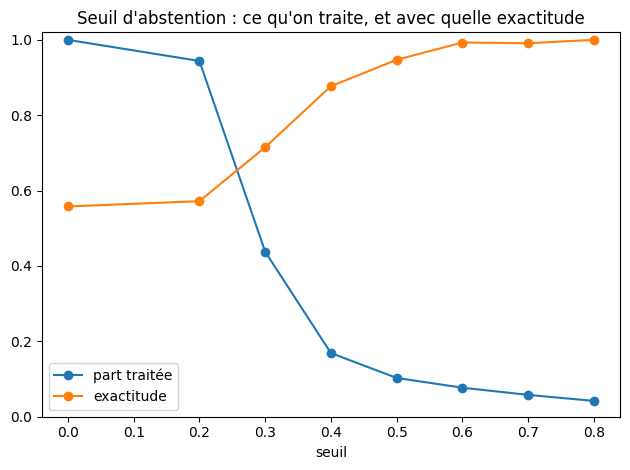

In [14]:
ax = courbe.plot(x="seuil", y=["part traitée", "exactitude"], marker="o",
                 title="Seuil d'abstention : ce qu'on traite, et avec quelle exactitude")
ax.set_ylim(0, 1.02); plt.tight_layout(); plt.show()

SEUIL_ABSTENTION = 0.5   # à ajuster d'après le tableau, puis à justifier dans semaine4.md

## 9. Un second modèle : la priorité

La priorité alimente la règle d'escalade : un incident `high` part tout de suite vers un technicien.
Le chiffre à surveiller est le **rappel de `high`** : un incident urgent classé `low` est l'erreur la plus coûteuse.

In [15]:
y_prio = df["priority"]
p_train, p_test = y_prio.loc[idx_train], y_prio.loc[idx_test]
modele_prio = Pipeline([
    ("tfidf", tfidf()),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=GRAINE)),
]).fit(x_train, p_train)
predits_prio = modele_prio.predict(x_test)
f1_prio = f1_score(p_test, predits_prio, average="macro")
print(f"Priorité : accuracy {accuracy_score(p_test, predits_prio):.3f}, F1 macro {f1_prio:.3f}\n")
print(classification_report(p_test, predits_prio, digits=3, zero_division=0))

Priorité : accuracy 0.657, F1 macro 0.646

              precision    recall  f1-score   support

        high      0.707     0.704     0.706       788
         low      0.576     0.624     0.599       346
      medium      0.645     0.621     0.633       702

    accuracy                          0.657      1836
   macro avg      0.643     0.650     0.646      1836
weighted avg      0.659     0.657     0.658      1836



## 10. Proposer une solution : le ticket passé le plus proche

La colonne `answer` contient la réponse d'un technicien. Pour un nouvel incident, on cherche, dans
la même queue, le ticket d'entraînement le plus semblable (similarité cosinus TF-IDF) et on montre
sa réponse : c'est la partie *retrieval* d'un RAG, sans LLM.

In [16]:
memoire = df.loc[idx_train, ["text", "queue", "answer"]].dropna(subset=["answer"]).reset_index(drop=True)
vect_memoire = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
matrice_memoire = vect_memoire.fit_transform(memoire["text"])
SEUIL_SIMILARITE = 0.15


def ticket_semblable(texte, queue=None):
    sims = cosine_similarity(vect_memoire.transform([texte]), matrice_memoire)[0]
    if queue is not None:
        sims = np.where(memoire["queue"].to_numpy() == queue, sims, -1)
    i = int(sims.argmax())
    if sims[i] < SEUIL_SIMILARITE:
        return None
    return {"similarite": round(float(sims[i]), 3), "ticket": memoire.loc[i, "text"][:150],
            "reponse": memoire.loc[i, "answer"][:400]}


def traiter(texte):
    """Ce que fera l'API : classer, prioriser, puis proposer une solution ou escalader."""
    proba = modele.predict_proba([texte])[0]
    queue, confiance = modele.classes_[proba.argmax()], float(proba.max())
    priorite = modele_prio.predict([texte])[0]
    if confiance < SEUIL_ABSTENTION:
        return {"queue": "INDETERMINE", "confiance": round(confiance, 3), "priorite": priorite,
                "decision": "escalade N1 : confiance sous le seuil", "solution": None}
    semblable = ticket_semblable(texte, queue)
    if priorite == "high":
        decision = "escalade immédiate : priorité haute (solution proposée en attendant)"
    elif semblable is None:
        decision = "escalade : aucun ticket semblable"
    else:
        decision = "solution proposée : l'utilisateur essaie, puis dit si c'est résolu"
    return {"queue": queue, "confiance": round(confiance, 3), "priorite": priorite,
            "decision": decision, "solution": semblable}

## 11. Tester sur des incidents réels

Des messages comme les écrivent les utilisateurs, jamais vus par le modèle. Les deux derniers sont
des pièges : un ticket en français (le modèle n'a appris que l'anglais) et du charabia.
Regardez la queue, la confiance et la décision : sont-elles celles qu'un technicien aurait prises ?

In [17]:
questions = [
    "My VPN keeps disconnecting every 10 minutes when I work from home",
    "I can't log in, my account is locked after too many password attempts",
    "Outlook stopped receiving emails since this morning",
    "The printer on the second floor shows offline and nothing prints",
    "Our production database server is down and the whole team is blocked, urgent!",
    "My laptop is extremely slow and the fan is very loud",
    "The website returns a 500 error when customers try to check out",
    "I was charged twice for my subscription this month",
    "The new software update crashes the application on startup",
    "I cannot access the shared drive anymore, permission denied",
    "Mon VPN ne se connecte plus depuis ce matin",
    "xqzvb wlkptr grombu",
]

resultats = pd.DataFrame([{"incident": q, **{k: v for k, v in traiter(q).items() if k != "solution"}}
                          for q in questions])
resultats

,incident,queue,confiance,priorite,decision
0,My VPN keeps disconnecting every 10 minutes when I work from home,INDETERMINE,0.252,medium,escalade N1 : confiance sous le seuil
1,"I can't log in, my account is locked after too many password attempts",INDETERMINE,0.284,medium,escalade N1 : confiance sous le seuil
2,Outlook stopped receiving emails since this morning,INDETERMINE,0.184,low,escalade N1 : confiance sous le seuil
3,The printer on the second floor shows offline and nothing prints,INDETERMINE,0.233,medium,escalade N1 : confiance sous le seuil
4,"Our production database server is down and the whole team is blocked, urgent!",INDETERMINE,0.239,high,escalade N1 : confiance sous le seuil
5,My laptop is extremely slow and the fan is very loud,INDETERMINE,0.255,low,escalade N1 : confiance sous le seuil
6,The website returns a 500 error when customers try to check out,INDETERMINE,0.254,medium,escalade N1 : confiance sous le seuil
7,I was charged twice for my subscription this month,INDETERMINE,0.358,low,escalade N1 : confiance sous le seuil
8,The new software update crashes the application on startup,INDETERMINE,0.309,medium,escalade N1 : confiance sous le seuil
9,"I cannot access the shared drive anymore, permission denied",INDETERMINE,0.168,medium,escalade N1 : confiance sous le seuil


In [18]:
# Le détail pour un incident : la réponse du ticket passé le plus proche
r = traiter(questions[0])
print(json.dumps(r, indent=2, ensure_ascii=False))

{
  "queue": "INDETERMINE",
  "confiance": 0.252,
  "priorite": "medium",
  "decision": "escalade N1 : confiance sous le seuil",
  "solution": null
}


In [19]:
# Votre propre incident
mon_incident = "Teams calls drop after a few minutes and the screen sharing freezes"
print(json.dumps(traiter(mon_incident), indent=2, ensure_ascii=False))

{
  "queue": "INDETERMINE",
  "confiance": 0.243,
  "priorite": "low",
  "decision": "escalade N1 : confiance sous le seuil",
  "solution": null
}


## 12. Sauvegarder

Les modèles restent **hors de Git** (`models/*.joblib`) ; la mesure, elle, est versionnée
(`models/metrics_tobi.json`), comme dans le cours.

In [20]:
Path("models").mkdir(exist_ok=True)
joblib.dump(modele, "models/tobi_queue.joblib")
joblib.dump(modele_prio, "models/tobi_priorite.joblib")

rappels = recall_score(y_test, predits, average=None, labels=modele.classes_, zero_division=0)
metriques = {
    "source": source,
    "date": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "filtres": {"language": "en", "type": "Incident", "min_par_queue": MIN_PAR_QUEUE},
    "n_train": int(len(x_train)), "n_test": int(len(x_test)),
    "classes": [str(c) for c in modele.classes_],
    "accuracy": round(float(accuracy_score(y_test, predits)), 4),
    "f1_macro": round(float(f1_macro), 4),
    "f1_pondere": round(float(f1_score(y_test, predits, average="weighted")), 4),
    "rappel_par_classe": {str(c): round(float(v), 4) for c, v in zip(modele.classes_, rappels)},
    "seuil_f1": SEUIL_F1,
    "seuil_abstention": SEUIL_ABSTENTION,
    "priorite_f1_macro": round(float(f1_prio), 4),
}
Path("models/metrics_tobi.json").write_text(json.dumps(metriques, indent=2, ensure_ascii=False),
                                            encoding="utf-8")
print(json.dumps(metriques, indent=2, ensure_ascii=False))

{
  "source": "huggingface:Tobi-Bueck/customer-support-tickets",
  "date": "2026-11-08T11:00:28+00:00",
  "filtres": {
    "language": "en",
    "type": "Incident",
    "min_par_queue": 200
  },
  "n_train": 7343,
  "n_test": 1836,
  "classes": [
    "Billing and Payments",
    "Customer Service",
    "Human Resources",
    "IT Support",
    "Product Support",
    "Returns and Exchanges",
    "Service Outages and Maintenance",
    "Technical Support"
  ],
  "accuracy": 0.5577,
  "f1_macro": 0.5922,
  "f1_pondere": 0.5621,
  "rappel_par_classe": {
    "Billing and Payments": 0.8348,
    "Customer Service": 0.4699,
    "Human Resources": 0.6304,
    "IT Support": 0.555,
    "Product Support": 0.4704,
    "Returns and Exchanges": 0.6667,
    "Service Outages and Maintenance": 0.8058,
    "Technical Support": 0.5296
  },
  "seuil_f1": 0.85,
  "seuil_abstention": 0.5,
  "priorite_f1_macro": 0.6459
}


## 13. Pour le compte rendu (`docs/semaine2.md`)

Répondez avec **vos** chiffres :
1. Le modèle bat-il nettement la référence naïve ? De combien en F1 macro ?
2. Quelles queues sont le mieux et le moins bien reconnues, et lesquelles se confondent ? Pourquoi
   (vocabulaire commun, queues qui se recouvrent comme *Technical Support* et *IT Support*) ?
3. Le F1 macro atteint-il 0,85 ? Sinon, est-ce le modèle ou les étiquettes qui limitent ?
4. Quel seuil d'abstention choisissez-vous, et combien d'incidents partent alors vers un humain ?
5. Le rappel de la priorité `high` est-il suffisant pour décider seul d'une escalade ?

## 14. Diagnostic : pourquoi les 12 incidents réels tombent tous en `INDETERMINE`

Premier run : F1 macro 0,592 (régression logistique) et 0,693 (LinearSVC), loin de 0,85. Surtout,
**les 12 incidents de test ont une confiance entre 0,17 et 0,36**, le charabia a la même confiance
qu'« Outlook ne reçoit plus » (0,184), et au seuil 0,5 seuls 10 % des tickets de test sont traités.
Quatre hypothèses, vérifiées une par une :

1. **Changement de distribution** : les tickets du jeu font 58 mots en médiane (des e-mails
   formels), nos questions en font 10. → on mesure le modèle sur le **sujet seul** (phrase courte).
2. **Régularisation trop forte** : LinearSVC bat la régression logistique de 10 points, ce qui
   suggère que `C=1` est trop faible. → on essaie plusieurs `C`.
3. **Confiances mal calibrées** : avec 8 classes, la régression logistique répartit sa probabilité.
   → on calibre LinearSVC et on compare la part de tickets au-dessus du seuil.
4. **Étiquettes qui se recouvrent** : *Technical / IT / Product Support* sont les confusions les plus
   fréquentes. → on regroupe les queues en familles, et on regarde les `tag_*`.

In [21]:
# 14.1 — Changement de distribution : le même modèle, sur le sujet seul (texte court)
test = df.loc[idx_test]
avec_sujet = test["subject"].notna() & (test["subject"].astype(str).str.split().str.len() >= 2)
sujets, verites_sujet = test.loc[avec_sujet, "subject"].astype(str), test.loc[avec_sujet, "queue"]
p_sujet = modele.predict_proba(sujets)
print(f"Mots par sujet : médiane {sujets.str.split().str.len().median():.0f}")
print(f"F1 macro, texte complet : {f1_score(y_test, modele.predict(x_test), average='macro'):.3f}")
print(f"F1 macro, sujet seul    : {f1_score(verites_sujet, modele.classes_[p_sujet.argmax(1)], average='macro'):.3f}")
print(f"Confiance médiane, texte complet : {np.median(modele.predict_proba(x_test).max(1)):.3f}")
print(f"Confiance médiane, sujet seul    : {np.median(p_sujet.max(1)):.3f}")

Mots par sujet : médiane 5
F1 macro, texte complet : 0.592
F1 macro, sujet seul    : 0.381
Confiance médiane, texte complet : 0.287
Confiance médiane, sujet seul    : 0.257


In [22]:
# 14.2 — Régularisation : plusieurs valeurs de C pour la régression logistique
lignes = []
for c in [1, 5, 20, 50]:
    m = Pipeline([("tfidf", tfidf()),
                  ("clf", LogisticRegression(C=c, max_iter=3000, class_weight="balanced",
                                             random_state=GRAINE))]).fit(x_train, y_train)
    conf = m.predict_proba(x_test).max(1)
    lignes.append({"C": c, "F1 macro": f1_score(y_test, m.predict(x_test), average="macro"),
                   "part conf ≥ 0,5": (conf >= 0.5).mean()})
pd.DataFrame(lignes).round(3)

,C,F1 macro,"part conf ≥ 0,5"
0,1,0.592,0.103
1,5,0.667,0.406
2,20,0.687,0.685
3,50,0.691,0.789


In [23]:
# 14.3 — LinearSVC calibré : le meilleur classifieur, avec une vraie probabilité pour l'abstention
from sklearn.calibration import CalibratedClassifierCV

svc_calibre = Pipeline([
    ("tfidf", tfidf()),
    ("clf", CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=GRAINE), cv=3)),
]).fit(x_train, y_train)
proba_svc = svc_calibre.predict_proba(x_test)
pred_svc = svc_calibre.classes_[proba_svc.argmax(1)]
print(f"F1 macro : {f1_score(y_test, pred_svc, average='macro'):.3f}")
conf_svc = proba_svc.max(1)
lignes = []
for s in [0.3, 0.4, 0.5, 0.6, 0.7]:
    garde = conf_svc >= s
    justes = pred_svc[garde] == y_test.to_numpy()[garde]
    lignes.append({"seuil": s, "part traitée": garde.mean(),
                   "exactitude": justes.mean() if garde.any() else np.nan})
pd.DataFrame(lignes).round(3)

F1 macro : 0.685


,seuil,part traitée,exactitude
0,0.3,0.987,0.688
1,0.4,0.883,0.726
2,0.5,0.663,0.776
3,0.6,0.442,0.858
4,0.7,0.254,0.914


In [24]:
# 14.4 — Étiquettes : regrouper les queues qui se recouvrent en familles
FAMILLES = {
    "Technical Support": "Technique",
    "IT Support": "Technique",
    "Product Support": "Technique",
    "Service Outages and Maintenance": "Panne de service",
    "Customer Service": "Client",
    "Returns and Exchanges": "Client",
    "Billing and Payments": "Facturation",
    "Human Resources": "RH",
}
y_train_f, y_test_f = y_train.map(FAMILLES), y_test.map(FAMILLES)
modele_familles = Pipeline([
    ("tfidf", tfidf()),
    ("clf", CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=GRAINE), cv=3)),
]).fit(x_train, y_train_f)
pred_f = modele_familles.predict(x_test)
print(f"F1 macro, {y_train_f.nunique()} familles : {f1_score(y_test_f, pred_f, average='macro'):.3f}\n")
print(classification_report(y_test_f, pred_f, digits=3, zero_division=0))

F1 macro, 5 familles : 0.728

                  precision    recall  f1-score   support

          Client      0.818     0.396     0.533       273
     Facturation      1.000     0.835     0.910       115
Panne de service      0.942     0.631     0.756       103
              RH      1.000     0.370     0.540        46
       Technique      0.836     0.979     0.902      1299

        accuracy                          0.849      1836
       macro avg      0.919     0.642     0.728      1836
    weighted avg      0.853     0.849     0.830      1836



In [25]:
# 14.5 — Les tags : contiennent-ils des catégories IT plus utiles que les queues ?
colonnes_tags = [c for c in df.columns if c.startswith("tag_")]
tags = df[colonnes_tags].melt(value_name="tag")["tag"].dropna()
tags = tags[tags.astype(str).str.lower() != "none"]
print(f"{tags.nunique()} tags différents sur {len(df)} incidents")
tags.value_counts().head(30)

683 tags différents sur 9179 incidents


tag
Performance      5072
Tech Support     4688
IT               4569
Bug              3931
Disruption       2571
Outage           2248
Security         2152
Network          1757
Technical        1552
Resolution       1526
Feedback         1462
Documentation    1338
Recovery         1127
Crash            1081
Hardware          684
Maintenance       604
Incident          565
Software          552
Billing           455
Virus             398
Feature           395
Account           344
Payment           343
Guidance          343
Integration       322
Support           321
Breach            311
Alert             300
Product           293
Customer          288
Name: count, dtype: int64

### 14.6 — Les 12 incidents, avec les modèles améliorés

On compare, pour chaque incident, la confiance du modèle de départ, du LinearSVC calibré
(8 queues) et du modèle par familles. Une amélioration réelle se voit ici : les incidents IT
doivent passer au-dessus du seuil, et le charabia doit rester en dessous.

In [26]:
def meilleure(m, q):
    p = m.predict_proba([q])[0]
    return f"{m.classes_[p.argmax()]} ({p.max():.2f})"

pd.DataFrame([{"incident": q,
               "départ (LogReg)": meilleure(modele, q),
               "LinearSVC calibré": meilleure(svc_calibre, q),
               "familles": meilleure(modele_familles, q)} for q in questions])

,incident,départ (LogReg),LinearSVC calibré,familles
0,My VPN keeps disconnecting every 10 minutes when I work from home,Product Support (0.25),Product Support (0.64),Technique (0.89)
1,"I can't log in, my account is locked after too many password attempts",Billing and Payments (0.28),Billing and Payments (0.44),Facturation (0.44)
2,Outlook stopped receiving emails since this morning,Customer Service (0.18),Technical Support (0.41),Technique (0.66)
3,The printer on the second floor shows offline and nothing prints,Product Support (0.23),Product Support (0.46),Technique (0.93)
4,"Our production database server is down and the whole team is blocked, urgent!",Technical Support (0.24),Technical Support (0.59),Technique (0.85)
5,My laptop is extremely slow and the fan is very loud,IT Support (0.25),Product Support (0.33),Technique (0.82)
6,The website returns a 500 error when customers try to check out,Returns and Exchanges (0.25),Technical Support (0.43),Technique (0.78)
7,I was charged twice for my subscription this month,Billing and Payments (0.36),Billing and Payments (0.66),Facturation (0.60)
8,The new software update crashes the application on startup,Product Support (0.31),Product Support (0.52),Technique (0.96)
9,"I cannot access the shared drive anymore, permission denied",Customer Service (0.17),Technical Support (0.28),Technique (0.71)


### 14.7 — Conclusion à reporter dans `docs/semaine2.md`

Remplissez avec vos chiffres :
- le gain de LinearSVC calibré et du regroupement en familles sur le F1 macro ;
- la chute entre texte complet et sujet seul : c'est l'écart entre les e-mails du jeu et les
  messages courts qu'écrira un utilisateur dans la page ;
- si les 12 incidents restent sous le seuil, la conclusion est que **ce jeu ne suffit pas seul pour
  un agent de premier niveau** : ses queues sont des services d'une entreprise fictive, pas des
  catégories d'incident IT. Le modèle de l'application reste alors celui du jeu de démonstration,
  et Tobi-Bueck sert de mesure sur données réelles (`train.py --reel`), comme Allociné dans le cours.

## 15. Deux corrections tirées du diagnostic

Le tableau 14.6 montre que **la confiance ne sépare pas un vrai incident du charabia** :
le modèle par familles donne « Technique (0,84) » à `xqzvb wlkptr grombu`. Raison : un texte sans
aucun mot connu donne un vecteur TF-IDF nul, et le modèle répond alors sa classe la plus probable
*a priori* (Technique = 71 % des incidents). L'abstention par seuil ne peut donc pas l'attraper.

1. **Garde-fou de vocabulaire** : si moins de la moitié des mots du message sont connus du modèle,
   `INDETERMINE`, quelle que soit la confiance.
2. **Des catégories IT** : les queues sont des services d'entreprise ; les `tag_*` contiennent de vraies
   catégories d'incident (*Network, Security, Hardware, Software, Account…*). On en tire une étiquette.

In [27]:
# 15.1 — Garde-fou : la part des mots du message que le modèle connaît
SEUIL_VOCABULAIRE = 0.5


def part_connue(texte, m):
    tfidf_m = m.named_steps["tfidf"]
    mots = [t for t in tfidf_m.build_analyzer()(texte) if " " not in t]   # unigrammes seulement
    return sum(t in tfidf_m.vocabulary_ for t in mots) / len(mots) if mots else 0.0


pd.DataFrame([{"incident": q, "mots connus": round(part_connue(q, modele_familles), 2),
               "garde-fou": "INDETERMINE" if part_connue(q, modele_familles) < SEUIL_VOCABULAIRE else "passe"}
              for q in questions])

,incident,mots connus,garde-fou
0,My VPN keeps disconnecting every 10 minutes when I work from home,1.00,passe
1,"I can't log in, my account is locked after too many password attempts",0.83,passe
2,Outlook stopped receiving emails since this morning,1.00,passe
3,The printer on the second floor shows offline and nothing prints,0.73,passe
4,"Our production database server is down and the whole team is blocked, urgent!",0.85,passe
5,My laptop is extremely slow and the fan is very loud,0.82,passe
6,The website returns a 500 error when customers try to check out,0.91,passe
7,I was charged twice for my subscription this month,1.00,passe
8,The new software update crashes the application on startup,0.89,passe
9,"I cannot access the shared drive anymore, permission denied",0.88,passe


In [28]:
# 15.2 — Une catégorie IT par incident, tirée des tags (la première règle qui correspond gagne)
REGLES_TAGS = [
    ("Sécurité", {"Security", "Virus", "Breach", "Malware", "Phishing"}),
    ("Réseau", {"Network", "Connectivity", "VPN"}),
    ("Matériel", {"Hardware", "Printer", "Device"}),
    ("Compte et accès", {"Account", "Login", "Access", "Password"}),
    ("Facturation", {"Billing", "Payment", "Refund", "Invoice"}),
    ("Logiciel", {"Software", "Bug", "Crash", "Update"}),
    ("Panne de service", {"Outage", "Disruption", "Maintenance"}),
]
colonnes_tags = [c for c in df.columns if c.startswith("tag_")]


def categorie_it(ligne):
    tags_ligne = {str(t).strip() for t in ligne[colonnes_tags] if pd.notna(t)}
    for categorie, mots in REGLES_TAGS:
        if tags_ligne & mots:
            return categorie
    return None


df["categorie_it"] = df.apply(categorie_it, axis=1)
trop_rares = df["categorie_it"].value_counts()[lambda s: s < 50].index
df.loc[df["categorie_it"].isin(trop_rares), "categorie_it"] = None   # trop peu d'exemples pour apprendre
print(f"Catégories écartées (moins de 50 incidents) : {list(trop_rares)}")
print(f"Incidents sans catégorie IT : {df['categorie_it'].isna().sum()} sur {len(df)}")
df["categorie_it"].value_counts()

Catégories écartées (moins de 50 incidents) : []
Incidents sans catégorie IT : 913 sur 9179


categorie_it
Logiciel            2803
Sécurité            2164
Réseau              1400
Panne de service     878
Matériel             385
Compte et accès      369
Facturation          267
Name: count, dtype: int64

In [29]:
# 15.3 — Le modèle sur ces catégories (même découpage : on garde les incidents de test d'avant)
avec_cat = df["categorie_it"].notna()
tr = [i for i in idx_train if avec_cat[i]]
te = [i for i in idx_test if avec_cat[i]]
modele_it = Pipeline([
    ("tfidf", tfidf()),
    ("clf", CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=GRAINE), cv=3)),
]).fit(df.loc[tr, "text"], df.loc[tr, "categorie_it"])
pred_it = modele_it.predict(df.loc[te, "text"])
y_it = df.loc[te, "categorie_it"]
print(f"{len(tr)} incidents d'entraînement, {len(te)} de test")
print(f"Référence naïve, F1 macro : {f1_score(y_it, [y_it.mode()[0]] * len(y_it), average='macro'):.3f}")
print(f"F1 macro, catégories IT : {f1_score(y_it, pred_it, average='macro'):.3f}\n")
print(classification_report(y_it, pred_it, digits=3, zero_division=0))

6605 incidents d'entraînement, 1661 de test
Référence naïve, F1 macro : 0.072
F1 macro, catégories IT : 0.788

                  precision    recall  f1-score   support

 Compte et accès      0.776     0.592     0.672        76
     Facturation      0.745     0.826     0.784        46
        Logiciel      0.812     0.932     0.868       557
        Matériel      0.857     0.587     0.697        92
Panne de service      0.741     0.716     0.728       176
          Réseau      0.843     0.779     0.809       289
        Sécurité      0.973     0.946     0.959       425

        accuracy                          0.848      1661
       macro avg      0.821     0.768     0.788      1661
    weighted avg      0.850     0.848     0.846      1661



In [30]:
# 15.4 — Les 12 incidents : catégorie IT + garde-fou + seuil
SEUIL_IT = 0.5


def traiter_it(q):
    p = modele_it.predict_proba([q])[0]
    connus = part_connue(q, modele_it)
    if connus < SEUIL_VOCABULAIRE:
        decision = "INDETERMINE (mots inconnus)"
    elif p.max() < SEUIL_IT:
        decision = "INDETERMINE (confiance basse)"
    else:
        decision = modele_it.classes_[p.argmax()]
    return {"incident": q, "proposé": modele_it.classes_[p.argmax()], "confiance": round(p.max(), 2),
            "mots connus": round(connus, 2), "décision": decision}


pd.DataFrame([traiter_it(q) for q in questions])

,incident,proposé,confiance,mots connus,décision
0,My VPN keeps disconnecting every 10 minutes when I work from home,Logiciel,0.42,1.00,INDETERMINE (confiance basse)
1,"I can't log in, my account is locked after too many password attempts",Compte et accès,0.78,0.83,Compte et accès
2,Outlook stopped receiving emails since this morning,Logiciel,0.62,1.00,Logiciel
3,The printer on the second floor shows offline and nothing prints,Logiciel,0.38,0.73,INDETERMINE (confiance basse)
4,"Our production database server is down and the whole team is blocked, urgent!",Panne de service,0.49,0.85,INDETERMINE (confiance basse)
5,My laptop is extremely slow and the fan is very loud,Logiciel,0.39,0.82,INDETERMINE (confiance basse)
6,The website returns a 500 error when customers try to check out,Logiciel,0.70,0.91,Logiciel
7,I was charged twice for my subscription this month,Facturation,0.52,1.00,Facturation
8,The new software update crashes the application on startup,Logiciel,0.85,0.89,Logiciel
9,"I cannot access the shared drive anymore, permission denied",Sécurité,0.62,0.88,Sécurité


### 15.5 — À reporter dans `semaine2.md`

- Le garde-fou de vocabulaire attrape-t-il le charabia sans bloquer les vrais incidents ?
- Les catégories tirées des tags donnent-elles un meilleur F1 macro que les 8 queues (0,592 / 0,685) ?
  Attention : ces étiquettes sont **construites par nous** à partir des tags ; il faut le dire, et
  regarder si une catégorie reste trop petite pour être apprise.
- Pour chacun des 12 incidents, la décision est-elle celle d'un technicien ?